# Modelagem
### 0. Imports e leitura do dataset

In [46]:
import pandas as pd
import numpy as np
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
)
from sklearn.metrics import f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
import optuna
from optuna.trial import TrialState
from sentence_transformers import SentenceTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import joblib
from pathlib import Path
import matplotlib.pyplot as plt

RANDOM_STATE = 42

In [47]:
df = pd.read_csv('../data/processed/df_02.csv')
print(df.shape)
df.head()

(12530, 2)


,frase,rotulo
0,Ainda estou esperando pelo meu cartão?,chegada_do_cartão
1,O que posso fazer se meu cartão ainda não cheg...,chegada_do_cartão
2,Eu tenho esperado por mais de uma semana. O ca...,chegada_do_cartão
3,Posso rastrear meu cartão enquanto está em pro...,chegada_do_cartão
4,"Como eu posso saber se vou receber meu cartão,...",chegada_do_cartão


### 1. Divisão treino e teste
Divisão estratificada pelo `rotulo` (80% treino / 20% teste), para os dois conjuntos manterem a mesma proporção de cada classe.

In [48]:
X = df['frase']
y = df['rotulo']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f'Treino: {X_train.shape[0]} frases')
print(f'Teste: {X_test.shape[0]} frases')

Treino: 10024 frases
Teste: 2506 frases


In [49]:
# Conferindo se a proporção de cada rótulo se manteve nos dois conjuntos
proporcoes = pd.DataFrame({
    'total': y.value_counts(normalize=True),
    'treino': y_train.value_counts(normalize=True),
    'teste': y_test.value_counts(normalize=True),
}).round(4)

print(f"Rótulos no treino: {y_train.nunique()} | no teste: {y_test.nunique()}")
proporcoes.head(10)

Rótulos no treino: 77 | no teste: 77


,total,treino,teste
rotulo,,,
aceitação_de_cartão,0.0075,0.0075,0.0076
alterar_pin,0.0125,0.0125,0.0124
apple_pay_ou_google_pay,0.0126,0.0126,0.0128
ativar_meu_cartão,0.0148,0.0149,0.0148
beneficiário_não_permitido,0.0152,0.0153,0.0152
cancelar_transferência,0.0152,0.0152,0.0152
cartão_comprometido,0.0100,0.0100,0.0100
cartão_engolido,0.0076,0.0076,0.0076
cartão_não_funcionando,0.0109,0.0110,0.0108


### 2. Representações do texto
Para a modelagem, no treino dos modelos, usarei a representação das frases em `TF-IDF` e em `Embeddings`:


- **Definição TF-IDF (Como explicado no notebook anterior):** \
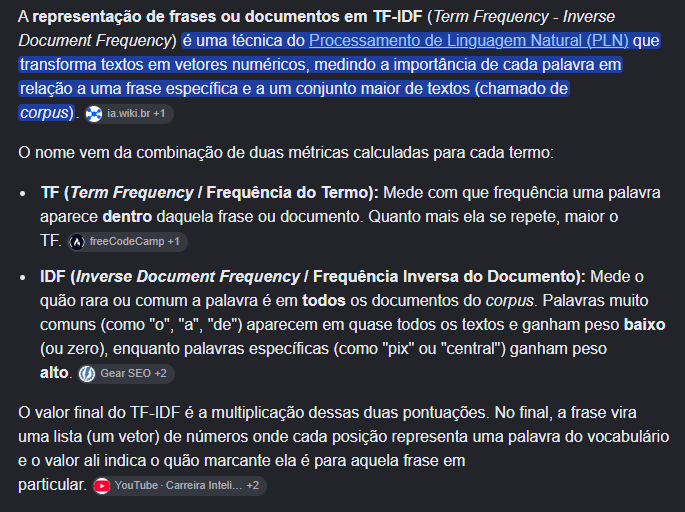

A ideia é dar um peso alto para uma palavra se ela for frequente em um documento e rara nos demais, e peso baixo se aparecer em quase todos, como as stopwords.

- **Definição Embeddings:** \
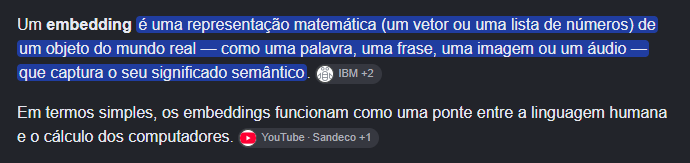

Esses vetores são construídos de modo que textos com significados parecidos fiquem próximos no espaço vetorial, mesmo quando usam palavras diferentes. No caso desse projeto, onde usarei embeddings de frases, o modelo lê a frase inteira e gera um único vetor para ela, levando em conta o contexto e a ordem das palavras. Diferente do TF-IDF, que depende da contagem de termos, essa representação capta relações semânticas, como sinônimos e paráfrases. Isso permite que classificadores simples, como a regressão logística, separem as intenções com base no significado das frases.
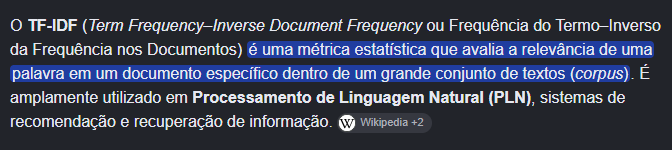
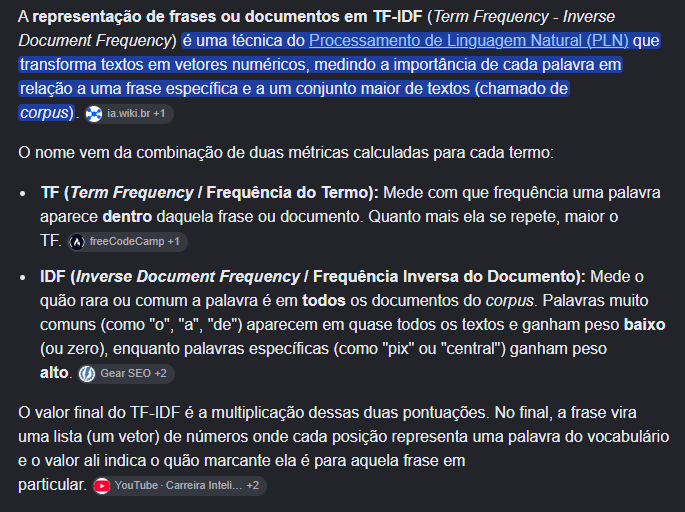

**Conjuntos utilizados**

Para a representação `TF-IDF`, testarei uma série de conjuntos (com GridSearch) para ver qual performa melhor, e registrarei aquele que obter melhor resultado.

Já para os `Embeddings`, vou comparar 3 encoders diferentes e registrar qual performa melhor:
- Serafim 335m, treinado apenas com palavras em português
- multilingual-e5-base, treino com multiplas linguas, mas com tamanho pequeno-médio
- multilingual-e5-large, mesmo modelo anterior, com tamanho maior


| Representação | Tipo                                    | O que a comparação isola            |
|---|-----------------------------------------|-------------------------------------|
| TF-IDF | esparsa                                 | efeito de ajuste de hiperparâmetros |
| Serafim 335m | embedding, em português | português vs. multilíngue (vs. e5)  |
| multilingual-e5-base | embedding, multilíngue                  | baseline de tamanho para o e5-large |
| multilingual-e5-large | embedding, multilíngue                  | efeito do tamanho do modelo (vs. e5-base) |

#### 2.1 TF-IDF com e sem stopwords
A lista de stopwords é a mesma do notebook 2, sem as negações (`não`, `nem`, `sem`), pois elas podem inverter o sentido das frases.

o TF-IDF é aprendido no treino e apenas aplicados no teste, para não haver data leakage.

In [50]:
# importando stopwords e removendo as negações
nltk.download('stopwords', quiet=True)

negacoes = {'não', 'nem', 'sem'}
stop_pt = set(stopwords.words('portuguese')) - negacoes

In [51]:
# Definindo treino e teste em formato TF-IDF, com e sem stopwords
# token_pattern mantém palavras de 1 caractere (o, a, é, 1), como no notebook 2
tfidf_com_stopw = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')
X_train_tfidf = tfidf_com_stopw.fit_transform(X_train)
X_test_tfidf = tfidf_com_stopw.transform(X_test)

tfidf_sem_stopw = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b', stop_words=sorted(stop_pt))
X_train_tfidf_sem_stopw = tfidf_sem_stopw.fit_transform(X_train)
X_test_tfidf_sem_stopw = tfidf_sem_stopw.transform(X_test)

print('Vocabulário com stopwords:', len(tfidf_com_stopw.vocabulary_))
print('Vocabulário sem stopwords:', len(tfidf_sem_stopw.vocabulary_))

Vocabulário com stopwords: 3097
Vocabulário sem stopwords: 2966


#### 2.2 Embeddings
Os modelos codificadores de embeddings que vou usar são:
- **Serafim 335m**: modelo treinado em português. Não usa prefixo nas frases.
- **multilingual-e5-base** e **multilingual-e5-large**: modelos multilingue. Ambos recebem o prefixo `"query: "` nas frases, pois esses modelos foram treinados com prefixos que indicam o papel de cada texto (`"query: "` para perguntas e `"passage: "` para documentos). Assim, os autores recomendam usar `"query: "` em todas as frases em tarefas de classificação.

Usarei as frases sem remover stopwords, pois esses modelos foram treinados com texto natural. Os vetores são normalizados (norma 1).

Como gerar os embeddings demora muito, vou salvá-los em `data/embeddings/` com os índices do treino e do teste. Se a divisão mudar (outro `random_state`, por exemplo), os embeddings são gerados de novo.

In [52]:
# Definição do nome e link de import dos embeddings
MODELOS_EMBEDDING = {
    'serafim_335m': {'nome': 'PORTULAN/serafim-335m-portuguese-pt-sentence-encoder', 'prefixo': ''},
    'e5_base': {'nome': 'intfloat/multilingual-e5-base', 'prefixo': 'query: '},
    'e5_large': {'nome': 'intfloat/multilingual-e5-large', 'prefixo': 'query: '},
}

PASTA_EMBEDDINGS = Path('../data/embeddings')
PASTA_EMBEDDINGS.mkdir(parents=True, exist_ok=True)

In [53]:
# Gera os embeddings de treino e teste de um modelo, ou carrega do disco se já existirem para a mesma divisão
def gerar_embeddings(chave, nome, prefixo, batch_size=32):
    arquivo = PASTA_EMBEDDINGS / f'{chave}.npz'

    if arquivo.exists():
        salvo = np.load(arquivo)
        mesma_divisao = (np.array_equal(salvo['idx_train'], X_train.index.values)
                         and np.array_equal(salvo['idx_test'], X_test.index.values))
        if mesma_divisao:
            print(f'{chave}: carregado de {arquivo}')
            return salvo['train'], salvo['test']
        print(f'{chave}: divisão diferente da salva, gerando de novo')

    modelo = SentenceTransformer(nome)
    def codificar(frases):
        return modelo.encode([prefixo + f for f in frases], batch_size=batch_size,
                             normalize_embeddings=True, show_progress_bar=True)

    emb_train = codificar(X_train)
    emb_test = codificar(X_test)

    np.savez(arquivo, train=emb_train, test=emb_test,
             idx_train=X_train.index.values, idx_test=X_test.index.values)
    print(f'{chave}: salvo em {arquivo}')
    return emb_train, emb_test

In [54]:
embeddings = {}
for chave, config in MODELOS_EMBEDDING.items():
    embeddings[chave] = gerar_embeddings(chave, config['nome'], config['prefixo'])

serafim_335m: carregado de ..\data\embeddings\serafim_335m.npz
e5_base: carregado de ..\data\embeddings\e5_base.npz
e5_large: carregado de ..\data\embeddings\e5_large.npz


#### 2.3 Conjunto de representações
Coloco todas as representações num único dicionário `{nome do conjunto : (X_train, X_test),}`

In [55]:
representacoes = {
    'tfidf_com_stopwords': (X_train_tfidf, X_test_tfidf),
    'tfidf_sem_stopwords': (X_train_tfidf_sem_stopw, X_test_tfidf_sem_stopw),
    **embeddings,
}

pd.DataFrame(
    [(nome, tr.shape[0], te.shape[0], tr.shape[1]) for nome, (tr, te) in representacoes.items()],
    columns=['representação', 'frases treino', 'frases teste', 'dimensões'],
)

,representação,frases treino,frases teste,dimensões
0,tfidf_com_stopwords,10024,2506,3097
1,tfidf_sem_stopwords,10024,2506,2966
2,serafim_335m,10024,2506,1024
3,e5_base,10024,2506,768
4,e5_large,10024,2506,1024


### 3. Baseline: TF-IDF + Regressão Logística sem ajuste
Crio um modelo baseline que será o ponto de referência para comparação de performance dos próximos modelos. Escolhi que esse baseline será:

**Regressão Logística sem ajuste de hiperparâmetros + TF-IDF apenas de unigramas, com stopwords**

#### Tabela de resultados
Definição de funçôes reutilizáveis de registro da performance de cada um dos modelos em uma tabela.

Todos os modelos avaliados são registrados tendo o baseline como referência. A coluna `ganho_f1_pp` mostra o ganho de cada modelo em pontos percentuais de F1-macro sobre o baseline. A coluna `f1_macro_cv` mostra o F1-macro na validação cruzada, que é o número usado para escolher cada modelo, ao lado do F1-macro no teste.

In [56]:
BASELINE = ('Regressão Logística (baseline)', 'TF-IDF')

resultados = {}

# Registra (ou substitui) o resultado de um modelo no teste
# f1_cv é o F1-macro do modelo na validação cruzada (o best_score_ da busca)
def registrar_resultado(modelo, representacao, y_true, y_pred, f1_cv=None):
    resultados[(modelo, representacao)] = {
        'modelo': modelo,
        'representação': representacao,
        'acurácia': accuracy_score(y_true, y_pred),
        'f1_macro_cv': f1_cv,
        'f1_macro': f1_score(y_true, y_pred, average='macro'),
    }

# Monta a tabela ordenada por F1-macro, com o ganho de cada modelo sobre o baseline
def tabela_resultados():
    tabela = pd.DataFrame(resultados.values())
    f1_baseline = resultados[BASELINE]['f1_macro']
    tabela['ganho_f1_pp'] = (tabela['f1_macro'] - f1_baseline) * 100
    return (tabela.sort_values('f1_macro', ascending=False)
                  .reset_index(drop=True)
                  .round({'acurácia': 4, 'f1_macro_cv': 4, 'f1_macro': 4, 'ganho_f1_pp': 2}))

#### Treino e avaliação

In [57]:
baseline_log_reg = LogisticRegression(max_iter=1000, C=1)
baseline_log_reg.fit(X_train_tfidf, y_train)
y_pred_baseline = baseline_log_reg.predict(X_test_tfidf)

print('Iterações até convergir:', baseline_log_reg.n_iter_[0])

Iterações até convergir: 36


In [58]:
# F1-macro do baseline na validação cruzada, com os mesmos folds das buscas da seção 4
# o TF-IDF fica dentro do pipeline para ser aprendido só com os folds de treino
cv_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipeline_baseline = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),
    ('clf', LogisticRegression(max_iter=1000, C=1)),
])

f1_cv_baseline = cross_val_score(pipeline_baseline, X_train, y_train, cv=cv_estratificado, scoring='f1_macro').mean()
print('F1-macro do baseline (CV):', round(f1_cv_baseline, 4))

F1-macro do baseline (CV): 0.8441


In [59]:
registrar_resultado(*BASELINE, y_test, y_pred_baseline, f1_cv_baseline)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.0


### 4. TF-IDF


 #### 4.1 Busca de hiperparâmetros

Os hiperparâmetros serão escolhidos com `GridSearchCV` usando apenas o conjunto de treino, com validação cruzada estratificada com 5 folds e F1-macro como critério de escolha.

Porém, o XGBoost será uma exceção. Usarei `Optuna` com os mesmos folds e o mesmo critério.

In [60]:
# Função reutilizável para aplicar GridSearch nos classificadores
# Cada resultado é salvo em ../data/buscas, com joblib (comprimido, pois as florestas da 4.4 ocupam alguns GB)
# Se o resultado já existir (mesmo grid e mesma divisão), a função carrega os resultados da pasta buscas pelo nome 'arquivo'
# X e y são opcionais: sem eles, a busca usa o texto do treino (TF-IDF). Na seção 5, recebe os embeddings do treino

def buscar(pipeline, arquivo, n_jobs, grade, X=None, y=None):
    arquivo = Path(arquivo)
    if X is None:
        X = X_train
    if y is None:
        y = y_train

    if arquivo.exists():
        salvo = joblib.load(arquivo)
        # comparo o texto das grades, pois objetos como StandardScaler() só são iguais a eles mesmos
        mesmo_grid = repr(salvo['busca'].param_grid) == repr(grade)
        # os embeddings seguem a ordem das frases do X_train (conferido na 2.2), então o índice vale para os dois
        mesma_divisao = np.array_equal(salvo['idx_train'], X_train.index.values)
        if mesmo_grid and mesma_divisao:
            busca = salvo['busca']
            print(f'Carregado de {arquivo}')
            print('Melhores parâmetros:', busca.best_params_)
            print('Melhor F1-macro (CV):', round(busca.best_score_, 4))
            return busca
        print(f'Grid ou divisão diferentes do salvo em {arquivo}, rodando de novo')

    busca = GridSearchCV(
        pipeline,
        param_grid=grade,
        cv=cv_estratificado,
        scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
        refit='f1_macro',
        n_jobs=n_jobs,
        verbose=1,
    )
    busca.fit(X, y)

    joblib.dump({'busca': busca, 'idx_train': X_train.index.values}, arquivo, compress=3)
    print(f'Salvo em {arquivo}')
    print('Melhores parâmetros:', busca.best_params_)
    print('Melhor F1-macro (CV):', round(busca.best_score_, 4))
    return busca

#### 4.2 Regressão Logística + TF-IDF
Aqui, testo as combinações:
- **n-gramas:** só unigramas, uni + bigramas ou uni + bi + trigramas.
- **Stopwords:** mantidas ou removidas (lista de remoção mantém as negações).
- **`min_df`:** a palavra precisa aparecer em pelo menos 1 ou 2 frases para entrar no vocabulário.
- **`sublinear_tf`:** com ou sem a troca do TF por 1 + ln(TF), que reduz o peso de palavras repetidas na mesma frase.
- **`class_weight`:** sem balanceamento de classes ou com, que dá mais peso aos erros nas classes com menos frases.
- **C (regularização):** valores [0.1, 1, 10 e 100] fixos. `C` é o inverso da força de regularização (valores menores = mais regularização).
    - **Regra:** Se o melhor C ficar no limite da grade (0.1 ou 100), faço uma segunda busca variando só o C, com os demais hiperparâmetros fixos, para ver se valores além desse limite são melhores.

Observações:
- Não usarei StandardScaler porque o TF-IDF já define o peso certo de cada palavra. Usá-lo distorceria esses pesos.
- Após a busca dos hiperparâmetros dessa seção, testarei regularização L1 e L2.

In [61]:
# 4.1 TF-IDF + Regressão Logística

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
    ('clf', LogisticRegression(max_iter=1000)),
])

grade_tfidf = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__stop_words': [None, sorted(stop_pt)],
    'tfidf__min_df': [1, 2],
    'tfidf__sublinear_tf': [False, True],
    'clf__C': [0.1, 1, 10, 100],
    'clf__class_weight': [None, 'balanced']

}

busca_reglog = buscar(
    pipeline,
    '../data/buscas/reglog_tfidf.joblib',
    n_jobs=3, grade=grade_tfidf)

Carregado de ..\data\buscas\reglog_tfidf.joblib
Melhores parâmetros: {'clf__C': 10, 'clf__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.8756


#### Teste de regularização
Testo regularização L2 utilizando os melhores hiperparâmetros encontrados no GridSearch do passo anterior para ver se há melhora de performance comparado ao L2

In [62]:
pipeline_penalty = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),
    ('clf', LogisticRegression(solver='saga', max_iter=5000)),
])

grade_penalty = {
    'tfidf__ngram_range': [busca_reglog.best_params_['tfidf__ngram_range']],
    'tfidf__stop_words': [busca_reglog.best_params_['tfidf__stop_words']],
    'tfidf__min_df': [busca_reglog.best_params_['tfidf__min_df']],
    'tfidf__sublinear_tf': [busca_reglog.best_params_['tfidf__sublinear_tf']],
    'clf__class_weight': ['balanced'],
    'clf__l1_ratio': [0, 1],          # 0 = L2, 1 = L1
    'clf__C': [1, 10, 100],
}

busca_penalty = buscar(
    pipeline_penalty,
    '../data/buscas/reglog_tfidf_penalty.joblib',
    n_jobs=3,
    grade=grade_penalty,
)

Carregado de ..\data\buscas\reglog_tfidf_penalty.joblib
Melhores parâmetros: {'clf__C': 10, 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.8749


##### O L1 não superou o L2. O L2 já é a regularização padrão da Regressão Logística no scikit-learn, e a sua força já tinha sido ajustada pelo `C` na busca anterior. Por isso, sigo com o modelo sem L1.

In [63]:
REGLOG_TFIDF = ('Regressão Logística ajustada', 'TF-IDF')

#### 4.3 LinearSVC + TF-IDF
Uso a mesma grade de TF-IDF da Regressão Logística, para que a comparação entre os dois modelos isole apenas o efeito do classificador:
- **n-gramas:** só unigramas, uni + bigramas ou uni + bi + trigramas.
- **Stopwords:** mantidas ou removidas (lista de remoção mantém as negações).
- **`min_df`:** a palavra precisa aparecer em pelo menos 1 ou 2 frases para entrar no vocabulário.
- **`sublinear_tf`:** com ou sem a troca do TF por 1 + ln(TF), que reduz o peso de palavras repetidas na mesma frase.
- **`class_weight`:** sem balanceamento de classes ou com, que dá mais peso aos erros nas classes com menos frases.
- **C (regularização):** valores [0.01, 0.1, 1 e 10]. Assim como na Regressão Logística, é o inverso da força de regularização (valores menores = margem mais larga e mais regularização). A grade começa mais baixa porque, no SVM, o melhor C com TF-IDF costuma ser menor.
    - **Regra:** Se o melhor C ficar no limite da grade (0.01 ou 10), faço uma segunda busca variando só o C, com os demais hiperparâmetros fixos, para ver se valores além desse limite são melhores.

Observações:
- Uso o kernel linear porque o TF-IDF gera vetores esparsos com milhares de dimensões. Nesse espaço as classes já costumam ser separáveis por um hiperplano, e os kernels RBF e polinomial raramente trazem ganho, além de serem bem mais lentos.
- Uso o `LinearSVC` em vez do `SVC(kernel='linear')`. O `LinearSVC` treina um classificador por classe (um contra todos, 77 modelos). O `SVC` treina um por par de classes (um contra um, 2.926 modelos), o que o torna bem mais lento com resultados praticamente iguais.
- `max_iter=5000` para garantir a convergência, principalmente com valores altos de C.
- Também não uso StandardScaler aqui, pelo mesmo motivo da Regressão Logística.

In [64]:
# 4.3 SVM + TF-IDF

pipeline_svm = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
    ('clf', SVC(cache_size=1000)),
])

grade_svm = [
    {
        'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
        'tfidf__stop_words': [None, sorted(stop_pt)],
        'tfidf__min_df': [1, 2],
        'tfidf__sublinear_tf': [False, True],
        'clf__kernel': ['linear'],
        'clf__C': [0.01, 0.1, 1, 10, 100],
        'clf__class_weight': [None, 'balanced']
    },
    {
        'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
        'tfidf__stop_words': [None, sorted(stop_pt)],
        'tfidf__min_df': [1, 2],
        'tfidf__sublinear_tf': [False, True],
        'clf__kernel': ['rbf'],
        'clf__C': [0.1, 1, 10, 100],
        'clf__gamma': ['scale', 0.1, 1, 10],
        'clf__class_weight': [None, 'balanced']
    },
    {
        'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
        'tfidf__stop_words': [None, sorted(stop_pt)],
        'tfidf__min_df': [1, 2],
        'tfidf__sublinear_tf': [False, True],
        'clf__kernel': ['poly'],
        'clf__C': [0.1, 1, 10, 100],
        'clf__degree': [2, 3],
        'clf__coef0': [0, 1],
        'clf__gamma': [1],
        'clf__class_weight': [None, 'balanced']
    },
]

busca_svm = buscar(
    pipeline_svm,
    '../data/buscas/svc_tfidf.joblib',
    n_jobs=6, grade=grade_svm)

Carregado de ..\data\buscas\svc_tfidf.joblib
Melhores parâmetros: {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__coef0': 1, 'clf__degree': 2, 'clf__gamma': 1, 'clf__kernel': 'poly', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.883


In [65]:
SVM_TFIDF = ('SVM ajustado', 'TF-IDF')

#### 4.4 Ensembles + TF-IDF
Nesta seção, decidi treinar modelos de ensemble baseados em árvores de decisão. Porém, o resultado esperado não é dos melhores, devido à forma como as árvores lidam com o TF-IDF.

O TF-IDF gera uma matriz esparsa, em que cada frase (linha) tem poucas palavras com valor diferente de 0, entre outras milhares de colunas, e cada palavra ajuda a indicar a classe. Os modelos lineares dão um peso para cada palavra em cada classe. Para classificar uma frase, eles somam os pesos de todas as palavras dela e escolhem a classe com a maior soma.

As árvores, por outro lado, dividem os dados olhando uma palavra por vez. Por isso, precisam de muitas divisões para chegar ao mesmo resultado. Como temos 77 classes, com poucas frases cada, as frases vão sendo separadas em grupos cada vez menores a cada divisão. No fim, sobram poucas frases em cada folha, e a árvore não tem exemplos suficientes para aprender o que cada palavra indica.

**Modelos escolhidos:**
- **Random Forest (Bagging):** treina várias árvores independentes, cada uma com uma amostra bootstrap das frases e um sorteio de palavras candidatas em cada divisão. A previsão final é o voto das árvores. A média de árvores diferentes reduz a variância de uma árvore sozinha.
- **XGBoost (Boosting):** treina as árvores em sequência, e cada nova árvore corrige os erros das anteriores. Reduz o viés, mas tem mais hiperparâmetros e é mais sensível a eles.

Observações:
- Para esses modelos, usarei a melhor configuração de hiperparâmetros do TF-IDF nos treinos da RegLog e do SVM (as duas buscas chegaram à mesma).
- Não uso StandardScaler, pois as árvores não dependem da escala das features.

In [66]:
# TF-IDF fixo na melhor configuração da busca do SVM e Regressão Logística
tfidf_fixo = {
    'tfidf__ngram_range': busca_svm.best_params_['tfidf__ngram_range'],
    'tfidf__stop_words': busca_svm.best_params_['tfidf__stop_words'],
    'tfidf__min_df': busca_svm.best_params_['tfidf__min_df'],
    'tfidf__sublinear_tf': busca_svm.best_params_['tfidf__sublinear_tf'],
}
tfidf_fixo

{'tfidf__ngram_range': (1, 1),
 'tfidf__stop_words': None,
 'tfidf__min_df': 1,
 'tfidf__sublinear_tf': True}

#### Random Forest + TF-IDF
Testo as combinações:
- **`max_features`:** quantas palavras são sorteadas como candidatas em cada divisão: `log2` ≈ 12, `sqrt` ≈ 56. Menos candidatas deixam as árvores mais diferentes entre si, e mais candidatas deixam cada árvore mais forte.
- **`min_samples_leaf`:** número mínimo de frases em cada folha: 1, 2 ou 4. Valores maiores deixam as árvores menores.
- **`class_weight`:** sem balanceamento de classes, `balanced` (pesos calculados no treino inteiro) ou `balanced_subsample` (pesos recalculados na amostra bootstrap de cada árvore).
    - **Regra:** Se o melhor `max_features` ficar no limite da grade (`log2` ou 5%), faço uma segunda busca variando só ele, com os demais hiperparâmetros fixos, para ver se valores além desse limite são melhores.
- **`max_depth`:** Profundidade máxima da árvore: None, 5 ou 10

Observações:
- Deixo `n_estimators=300` fixo

In [122]:
# 4.4.1 Random Forest + TF-IDF

pipeline_rf = Pipeline([
    ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
    ('clf', RandomForestClassifier(n_estimators=300, n_jobs=10, random_state=RANDOM_STATE)),
])

grade_rf = {
    'tfidf__ngram_range': [tfidf_fixo['tfidf__ngram_range']],
    'tfidf__stop_words': [tfidf_fixo['tfidf__stop_words']],
    'tfidf__min_df': [tfidf_fixo['tfidf__min_df']],
    'tfidf__sublinear_tf': [tfidf_fixo['tfidf__sublinear_tf']],
    'clf__max_features': ['log2', 'sqrt'],
    #'clf__min_samples_leaf': [1, 2, 4], # testei com esse ao invés do max_depth mas deu o mesmo f1-macro na cross-validation (0.8487)
    'clf__max_depth': [None, 5, 10],
    'clf__class_weight': [None, 'balanced'],
}

busca_rf = buscar(
    pipeline_rf,
    '../data/buscas/rf_tfidf.joblib',
    n_jobs=1, grade=grade_rf)

Carregado de ..\data\buscas\rf_tfidf.joblib
Melhores parâmetros: {'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'log2', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.8487
Carregado de ..\data\buscas\rf_tfidf.joblib
Melhores parâmetros: {'clf__class_weight': 'balanced', 'clf__max_depth': None, 'clf__max_features': 'log2', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__sublinear_tf': True}
Melhor F1-macro (CV): 0.8487


In [123]:
RF_TFIDF = ('Random Forest ajustado', 'TF-IDF')

#### XGBoost + TF-IDF (com Optuna)
Como o XGBoost tem muitos hiperparâmetros contínuos, o treino usando GridSearch dariam muitas combinações e custaria muito tempo. Por isso, usarei o `Optuna` para esse ajuste.

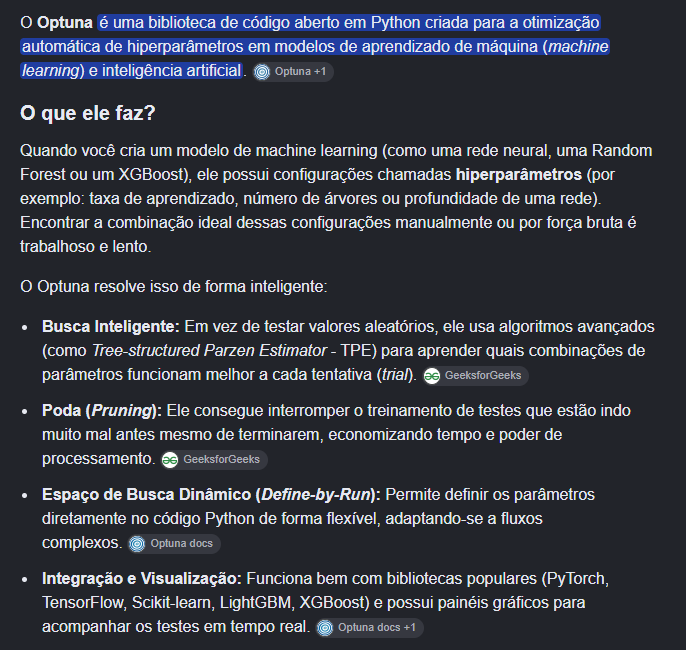

Faixas e hiperparametros testados:
- **`n_estimators`:** número de rodadas de boosting, de 100 a 1000. Na primeira busca, de 100 a 400, o melhor valor ficou no teto (400), sinal de que mais rodadas ainda poderiam ajudar, então ampliei o intervalo.
- **`learning_rate`:** quanto cada árvore corrige das anteriores, de 0,03 a 0,3 (escala log). Valores menores precisam de mais rodadas.
- **`max_depth`:** profundidade máxima de cada árvore, de 3 a 8.
- **`min_child_weight`:** soma mínima da hessiana (o "peso" das frases) em cada folha, de 0,01 a 2 (escala log).
- **`subsample`:** fração das frases sorteada para cada rodada, de 0,6 a 1.
- **`colsample_bytree`:** fração das palavras sorteada para cada árvore, de 0,3 a 1.
- **`reg_lambda` e `reg_alpha`:** regularização L2 e L1 dos pesos das folhas, de 0,001 a 10 (escala log).
- **Balanceamento:** sem ou com pesos por classe, equivalente ao `class_weight`.

Observações:
- O XGBoost não tem `class_weight`. O equivalente ao `balanced` é passar um peso para cada frase com `compute_sample_weight('balanced', y)` no `fit`.
- O XGBoost exige rótulos inteiros (0 a 76), então codifico os rótulos com `LabelEncoder` e decodifico as previsões no final.
- Como esse ajuste leva muitas horas, para esse caso utilizei IA para adaptar o código para salvar o progresso da busca em `../data/buscas` com joblib a cada tentativa. Portanto, ela pode ser interrompida e continua de onde parou em uma nova execução. Depois da busca, o modelo final é treinado no treino inteiro com os melhores hiperparâmetros.

In [124]:
# Função reutilizável para aplicar Optuna nos classificadores, no mesmo formato da buscar
# O estudo é salvo em ../data/buscas, com joblib, a cada tentativa
# Se o arquivo já existir (mesma divisão), carrega o estudo e só roda as tentativas que faltam para chegar em n_tentativas
# ajustar_final recebe os melhores hiperparâmetros e devolve o modelo treinado no treino inteiro

def buscar_optuna(objetivo, ajustar_final, arquivo, n_tentativas):
    arquivo = Path(arquivo)
    estudo, modelo = None, None

    if arquivo.exists():
        salvo = joblib.load(arquivo)
        if np.array_equal(salvo['idx_train'], X_train.index.values):
            estudo, modelo = salvo['estudo'], salvo['modelo']
            print(f'Carregado de {arquivo}')
        else:
            print(f'Divisão diferente da salva em {arquivo}, rodando de novo')

    if estudo is None:
        estudo = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=8),
        )

    def salvar(estudo, modelo=None):
        joblib.dump({'estudo': estudo, 'modelo': modelo, 'idx_train': X_train.index.values}, arquivo, compress=3)

    feitas = len(estudo.get_trials(states=(TrialState.COMPLETE, TrialState.PRUNED)))
    if feitas < n_tentativas:
        modelo = None  # o melhor resultado pode mudar, então o modelo final é treinado de novo
        estudo.optimize(objetivo, n_trials=n_tentativas - feitas,
                        callbacks=[lambda estudo, tentativa: salvar(estudo)])

    if modelo is None:
        modelo = ajustar_final(estudo.best_params)
        salvar(estudo, modelo)
        print(f'Salvo em {arquivo}')

    podadas = len(estudo.get_trials(states=(TrialState.PRUNED,)))
    print(f'Tentativas: {len(estudo.trials)} ({podadas} podadas)')
    print('Melhores parâmetros:', estudo.best_params)
    print('Melhor F1-macro (CV):', round(estudo.best_value, 4))
    return estudo, modelo

In [125]:
# 4.4.2 XGBoost + TF-IDF

codificador = LabelEncoder().fit(y_train)
y_train_cod = codificador.transform(y_train)

# Pipeline com o TF-IDF fixo e os hiperparâmetros do XGBoost
def pipeline_xgb(params):
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')),  # fixo
        ('clf', XGBClassifier(**params, tree_method='hist', n_jobs=10, random_state=RANDOM_STATE)),
    ])
    return pipeline.set_params(**tfidf_fixo)

# Pesos por frase, equivalentes ao class_weight='balanced'
def pesos(y, balanceado):
    return compute_sample_weight('balanced', y) if balanceado else None

# F1-macro médio nos 5 folds para os hiperparâmetros sorteados pelo Optuna
def objetivo_xgb(tentativa):
    params = {
        'n_estimators': tentativa.suggest_int('n_estimators', 100, 1000, step=50),
        'learning_rate': tentativa.suggest_float('learning_rate', 0.03, 0.3, log=True),
        'max_depth': tentativa.suggest_int('max_depth', 3, 8),
        'min_child_weight': tentativa.suggest_float('min_child_weight', 0.01, 2, log=True),
        'subsample': tentativa.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': tentativa.suggest_float('colsample_bytree', 0.3, 1.0),
        'reg_lambda': tentativa.suggest_float('reg_lambda', 1e-3, 10, log=True),
        'reg_alpha': tentativa.suggest_float('reg_alpha', 1e-3, 10, log=True),
    }
    balanceado = tentativa.suggest_categorical('balanceado', [False, True])

    f1_folds = []
    for fold, (idx_tr, idx_val) in enumerate(cv_estratificado.split(X_train, y_train)):
        modelo = pipeline_xgb(params)
        modelo.fit(X_train.iloc[idx_tr], y_train_cod[idx_tr],
                   clf__sample_weight=pesos(y_train_cod[idx_tr], balanceado))
        y_pred = modelo.predict(X_train.iloc[idx_val])
        f1_folds.append(f1_score(y_train_cod[idx_val], y_pred, average='macro'))

        # o pruner compara o F1-macro médio até este fold com o das outras tentativas
        tentativa.report(np.mean(f1_folds), fold)
        if tentativa.should_prune():
            raise optuna.TrialPruned()

    return np.mean(f1_folds)

# Modelo final: melhores hiperparâmetros, treinado no treino inteiro
def ajustar_xgb(melhores):
    params = {k: v for k, v in melhores.items() if k != 'balanceado'}
    modelo = pipeline_xgb(params)
    modelo.fit(X_train, y_train_cod, clf__sample_weight=pesos(y_train_cod, melhores['balanceado']))
    return modelo

In [126]:
estudo_xgb, modelo_xgb = buscar_optuna(
    objetivo_xgb, ajustar_xgb,
    '../data/buscas/xgb_tfidf.joblib',
    n_tentativas=40)

Carregado de ..\data\buscas\xgb_tfidf.joblib
Tentativas: 40 (6 podadas)
Melhores parâmetros: {'n_estimators': 550, 'learning_rate': 0.06309192381879594, 'max_depth': 3, 'min_child_weight': 0.010263458181313006, 'subsample': 0.7800708710036899, 'colsample_bytree': 0.5418196475619211, 'reg_lambda': 0.004378845862481423, 'reg_alpha': 0.003106078492393007, 'balanceado': False}
Melhor F1-macro (CV): 0.8228


In [127]:
XGB_TFIDF = ('XGBoost ajustado', 'TF-IDF')

#### 4.5 Estudo de hiperparâmetros dos melhores modelos
Para medir o efeito de cada hiperparâmetro do TF-IDF e do classificador, parto da melhor configuração dos dois modelos que performaram melhor:

- Regressão Logística
- SVM

Altero um elemento por vez, mantendo os outros fixos. No SVM, os fatores fixos incluem o kernel polinomial e seus parâmetros. O F1-macro de cada variação já está guardado no `cv_results_`, por isso uso esses dados para fazer essa análise.

In [128]:
FATORES = ['tfidf__ngram_range', 'tfidf__stop_words', 'tfidf__min_df',
           'tfidf__sublinear_tf', 'clf__class_weight', 'clf__C']

# Troca o None, a lista de stopwords e o scaler por nomes que dá para ler na tabela
def nome_valor(fator, valor):
    if fator == 'tfidf__stop_words':
        if valor is None:
            return 'mantidas'
        return 'removidas'
    if fator == 'clf__class_weight':
        if valor is None:
            return 'nenhum'
        return valor
    if fator == 'scaler':
        if valor == 'passthrough':
            return 'sem'
        return 'com'
    return str(valor)

# F1-macro de cada um dos 5 folds para a configuração i da busca
def f1_dos_folds(busca, i):
    return np.array([busca.cv_results_[f'split{k}_test_f1_macro'][i] for k in range(5)])

# Configurações da grade em que só o fator muda e os outros ficam iguais aos da melhor configuração
# Devolve {valor do fator: índice da configuração no cv_results_}
# No kernel do SVM, comparo só os parâmetros que todos os kernels têm (C, class_weight e scaler), pois
# o linear não tem gamma e só o polinomial tem degree e coef0. Para cada kernel, fico com a melhor combinação
def variacoes(busca, fator):
    melhor = busca.best_params_
    resultados = busca.cv_results_
    ignorar = {fator}
    if fator == 'clf__kernel':
        ignorar = ignorar | {'clf__gamma', 'clf__degree', 'clf__coef0'}

    escolhidas = {}
    for i, params in enumerate(resultados['params']):
        outros_iguais = True
        for p in melhor:
            # uso get porque nem todo kernel tem gamma, degree e coef0
            if p not in ignorar and params.get(p) != melhor[p]:
                outros_iguais = False
        if not outros_iguais:
            continue

        valor = nome_valor(fator, params[fator])
        if valor not in escolhidas or resultados['mean_test_f1_macro'][i] > resultados['mean_test_f1_macro'][escolhidas[valor]]:
            escolhidas[valor] = i
    return escolhidas

# Tabela com o F1-macro de cada variação e a diferença para a melhor configuração
def ablacao(busca, fatores):
    resultados = busca.cv_results_
    folds_melhor = f1_dos_folds(busca, busca.best_index_)

    linhas = []
    for fator in fatores:
        for valor, i in variacoes(busca, fator).items():
            f1 = resultados['mean_test_f1_macro'][i]
            folds = f1_dos_folds(busca, i)
            linhas.append({
                'fator': fator.split('__')[-1],
                'valor': valor,
                'f1_macro_cv': f1,
                'dif_pp': (f1 - busca.best_score_) * 100,  # diferença para a melhor, em pontos percentuais
                'folds_pior': int(np.sum(folds < folds_melhor)),  # em quantos folds ficou abaixo da melhor
            })

    return pd.DataFrame(linhas).set_index(['fator', 'valor'])

In [129]:
ablacao_reglog = ablacao(busca_reglog, FATORES)
ablacao_svm = ablacao(busca_svm, FATORES)

# Regressão Logística (4 casas no F1-macro e 2 na diferença em pp)
print('Estudo de Hiperparâmetros - Regressão Logística')
ablacao_reglog.round({'f1_macro_cv': 4, 'dif_pp': 2})

Estudo de Hiperparâmetros - Regressão Logística


f1_macro_cv  dif_pp  folds_pior
fator        valor                                     
ngram_range  (1, 1)          0.8756    0.00           0
             (1, 2)          0.8733   -0.23           3
             (1, 3)          0.8592   -1.64           5
stop_words   mantidas        0.8756    0.00           0
             removidas       0.8607   -1.49           5
min_df       1               0.8756    0.00           0
             2               0.8723   -0.33           4
sublinear_tf False           0.8736   -0.20           4
             True            0.8756    0.00           0
class_weight nenhum          0.8743   -0.13           3
             balanced        0.8756    0.00           0
C            0.1             0.7492  -12.64           5
             1               0.8476   -2.80           5
             10              0.8756    0.00           0
             100             0.8716   -0.39           4

In [130]:
# SVM
print('Estudo de Hiperparâmetros - SVM')
ablacao_svm.round({'f1_macro_cv': 4, 'dif_pp': 2})

Estudo de Hiperparâmetros - SVM


f1_macro_cv  dif_pp  folds_pior
fator        valor                                     
ngram_range  (1, 1)          0.8830    0.00           0
             (1, 2)          0.8735   -0.95           5
             (1, 3)          0.8595   -2.36           5
stop_words   mantidas        0.8830    0.00           0
             removidas       0.8699   -1.32           5
min_df       1               0.8830    0.00           0
             2               0.8804   -0.26           3
sublinear_tf False           0.8823   -0.07           5
             True            0.8830    0.00           0
class_weight nenhum          0.8820   -0.10           5
             balanced        0.8830    0.00           0
C            0.1             0.8468   -3.63           5
             1               0.8830    0.00           0
             10              0.8782   -0.49           5
             100             0.8780   -0.51           5

#### Comparação entre folds
O gráfico abaixo mostra cada fold separadamente:

- Cada linha cinza é um fold e a linha azul é a média dos 5. O eixo y é a diferença de F1-macro para a melhor configuração, em pontos percentuais, calculada dentro de cada fold.
- O rótulo acima de cada ponto é o `folds_pior` das tabelas (em quantos dos 5 folds a variação ficou abaixo da melhor).

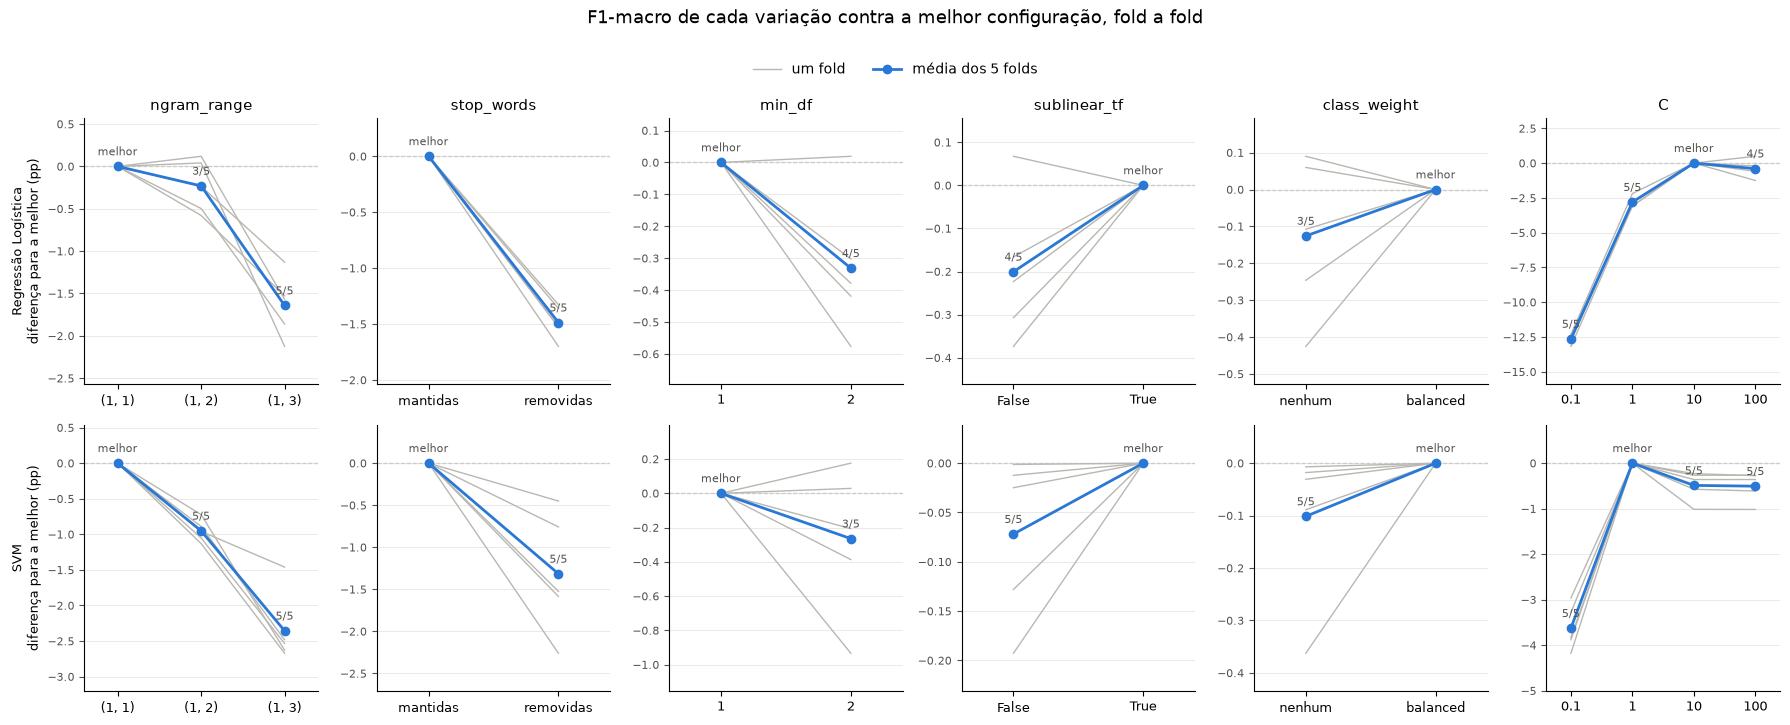

In [131]:
# Diferença de cada variação para a melhor configuração, fold a fold, em pp
# Mesma seleção da ablacao: só o fator muda, os outros ficam na melhor configuração
def difs_por_fold(busca, fatores):
    folds_melhor = f1_dos_folds(busca, busca.best_index_)

    linhas = []
    for fator in fatores:
        for valor, i in variacoes(busca, fator).items():
            difs = (f1_dos_folds(busca, i) - folds_melhor) * 100
            for k, dif in enumerate(difs):
                linhas.append({
                    'fator': fator.split('__')[-1],
                    'valor': valor,
                    'fold': k,
                    'dif_pp': dif,
                })
    return pd.DataFrame(linhas)

COR_FOLD = '#b8b7b1'   # cinza: os folds não precisam de cor própria
COR_MEDIA = '#2a78d6'  # azul: média dos 5 folds
COR_TEXTO = '#52514e'

# Um painel por fator (colunas) e por modelo (linhas), cada um com a sua escala
def grafico_folds(buscas, fatores):
    fig, eixos = plt.subplots(len(buscas), len(fatores), figsize=(3 * len(fatores), 3.4 * len(buscas)),
                              squeeze=False)

    for linha, (modelo, busca) in enumerate(buscas.items()):
        difs = difs_por_fold(busca, fatores)

        for coluna, fator in enumerate(fatores):
            ax = eixos[linha, coluna]
            dados = difs[difs['fator'] == fator.split('__')[-1]]
            valores = list(dict.fromkeys(dados['valor']))  # na ordem da grade
            x = np.arange(len(valores))

            # uma linha por fold
            for k in range(5):
                fold = dados[dados['fold'] == k].set_index('valor').loc[valores, 'dif_pp']
                ax.plot(x, fold, color=COR_FOLD, linewidth=1, zorder=1)

            # média dos folds
            media = dados.groupby('valor', sort=False)['dif_pp'].mean().loc[valores]
            ax.plot(x, media, color=COR_MEDIA, linewidth=2, marker='o', markersize=6, zorder=2)

            # em quantos folds cada variação ficou abaixo da melhor
            for xi, valor in zip(x, valores):
                folds_pior = int((dados.loc[dados['valor'] == valor, 'dif_pp'] < 0).sum())
                if media[valor] == 0:
                    rotulo = 'melhor'
                else:
                    rotulo = f'{folds_pior}/5'
                ax.annotate(rotulo, (xi, media[valor]), textcoords='offset points', xytext=(0, 8),
                            ha='center', fontsize=8, color=COR_TEXTO)

            ax.axhline(0, color=COR_TEXTO, linewidth=0.8, linestyle='--', zorder=0)
            ax.set_xticks(x, valores, fontsize=9)
            ax.set_xlim(-0.4, len(valores) - 0.6)
            ax.margins(y=0.2)
            ax.tick_params(axis='y', labelsize=8, colors=COR_TEXTO)
            ax.grid(axis='y', color='#e6e5e0', linewidth=0.6)
            ax.set_axisbelow(True)
            for lado in ['top', 'right']:
                ax.spines[lado].set_visible(False)

            if linha == 0:
                ax.set_title(fator.split('__')[-1], fontsize=11)
            if coluna == 0:
                ax.set_ylabel(f'{modelo}\ndiferença para a melhor (pp)', fontsize=9)

    fig.legend(
        [plt.Line2D([], [], color=COR_FOLD, linewidth=1),
         plt.Line2D([], [], color=COR_MEDIA, linewidth=2, marker='o')],
        ['um fold', 'média dos 5 folds'],
        loc='upper center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0),
    )
    fig.suptitle('F1-macro de cada variação contra a melhor configuração, fold a fold', y=1.06, fontsize=13)
    fig.tight_layout()
    return fig

grafico_folds({'Regressão Logística': busca_reglog, 'SVM': busca_svm}, FATORES)
plt.show()

**Baseline como referência**

Resultados do baseline para efeito de comparação

In [132]:
# Ganho dos modelos ajustados sobre o baseline, todos na validação cruzada com os mesmos folds
ganho_reglog = (busca_reglog.best_score_ - f1_cv_baseline) * 100
ganho_svm = (busca_svm.best_score_ - f1_cv_baseline) * 100

print('F1-macro do baseline (CV):', round(f1_cv_baseline, 4))
print(f'Ganho da Regressão Logística ajustada: {ganho_reglog:.2f} pp')
print(f'Ganho do SVM ajustado: {ganho_svm:.2f} pp')

F1-macro do baseline (CV): 0.8441
Ganho da Regressão Logística ajustada: 3.15 pp
Ganho do SVM ajustado: 3.89 pp


**Conclusão**

O ajuste levou a Regressão Logística de 0,8441 para 0,8756 de F1-macro na validação cruzada (+3,15 pp). O hiperparâmetro `C` explica quase todo esse ganho, pois com os outros fatores na melhor configuração e `C=1` (como no baseline), o modelo deixa de ganhar 2,80 pp no f1-macro, comparado com o `C` ajustado (= 10). No SVM, o `C` também é o fator de maior efeito (`C=0,1` custa 3,63 pp).

Entre os fatores do TF-IDF, só dois têm efeito claro, nos dois modelos e em 5 de 5 folds:

- Remover as stopwords (−1,3 a −1,5 pp)
- Usar trigramas (−1,6 a −2,4 pp)

Os demais mudam o F1-macro em 0,3 pp ou menos, com exceção dos bigramas no SVM (−0,95 pp).

**Hipóteses do notebook 02**

| Hipótese                                                                 | Resultado                                                                                                                                                                    |
|--------------------------------------------------------------------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Bigramas e trigramas separam rótulos que compartilham as mesmas palavras | **Negativo** - Unigramas foram a melhor opção nos dois modelos. Bigramas custaram 0,23 pp na Regressão Logística e 0,95 pp no SVM. Já os trigramas custam de 1,6 a 2,4 pp.   |
| Testar com e sem stopwords (sem as negações)                             | **Manter as stopwords é melhor** - Removê-las custa de 1,3 a 1,5 pp, em 5 de 5 folds nos dois modelos.                                                                       |
| Testar `min_df=2` (descartar termos que aparecem uma vez só)             | **Negativo** - A diferença é de cerca de 0,3 pp.                                                                                                                             |
| `sublinear_tf=True` reduz o peso das palavras repetidas                  | **Confirmado, porém o efeito é desprezível** (0,07 a 0,2 pp).                                                                                                                |
| Testar balanceamento de classes dos rótulos (`class_weight='balanced'`)  | **Balanceamento ajuda, porém o é efeito muito pequeno** (cerca de 0,1 pp). A razão entre o maior e o menor rótulo é de 3,2, o que não chega a prejudicar os rótulos menores. |

#### 4.6 Avaliação no teste
Com o ajuste dos hiperparâmetros feito com a validação cruzada no treino, avalio os modelos no conjunto de teste e registro os resultados na tabela.

In [133]:
y_pred_reglog_tfidf = busca_reglog.predict(X_test)

registrar_resultado(*REGLOG_TFIDF, y_test, y_pred_reglog_tfidf, busca_reglog.best_score_)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
1,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00


In [134]:
y_pred_svm_tfidf = busca_svm.predict(X_test)

registrar_resultado(*SVM_TFIDF, y_test, y_pred_svm_tfidf, busca_svm.best_score_)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
1,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
2,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00


In [135]:
y_pred_rf_tfidf = busca_rf.predict(X_test)

registrar_resultado(*RF_TFIDF, y_test, y_pred_rf_tfidf, busca_rf.best_score_)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
1,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
2,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00
3,Random Forest ajustado,TF-IDF,0.8579,0.8487,0.8558,-0.97


In [136]:
y_pred_xgb_tfidf = codificador.inverse_transform(modelo_xgb.predict(X_test))

registrar_resultado(*XGB_TFIDF, y_test, y_pred_xgb_tfidf, estudo_xgb.best_value)
tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
1,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
2,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00
3,Random Forest ajustado,TF-IDF,0.8579,0.8487,0.8558,-0.97
4,XGBoost ajustado,TF-IDF,0.8312,0.8228,0.8313,-3.42


**Comparação entre validação cruzada e teste**

- Em todos os casos, o f1-macro do teste ficou acima do f1-macro na validação cruzada. Provavelmente, isso se da pois o modelo final é treinado com o treino inteiro, enquanto em cada fold o modelo treina com 80% dele.
- SVM e Regressão Logística ajustados ficaram na frente, e os modelos de ensemble em último, como esperado.
- No teste, a diferença entre o SVM e a Regressão Logística é de 0,16 pp de F1-macro e de 0,08 de acurácia. Na prática, os dois modelos empatam.

### 5. Embeddings

#### 5.1 Ajuste de hiperparâmetros

Para o ajuste dos hiperparâmetros, seguirei os mesmos passos da busca com TF-IDF:
- Usarei `GridSearchCV` com os 5 folds (`cv_estratificado`) e F1-macro como critério de escolha. Como os folds serão os mesmos, poderei comparar os encoders entre si, e com o TF-IDF, fold a fold.
- Se o melhor `C` for o do limite da grade, faço uma segunda busca variando só `C`, com um intervalo mais amplo, mantendo os outros hiperparâmetros fixos.
- Cada busca será salva em `data/buscas/` com o nome `<modelo>_<encoder>.joblib` (exemplo: `reglog_e5_large.joblib`).

#### 5.2 Regressão Logística + Embeddings
Faço uma busca para cada encoder, todas com a mesma grade:
- **C (regularização):** valores [0.1, 1, 10 e 100], mesmos da Regressão Logística com TF-IDF.
- **`class_weight`:** com ou sem balanceamento de classes.
- **`StandardScaler`:** com ou sem padronização das dimensões.

Observações:
- No TF-IDF não usei o `StandardScaler`, porque ele distorceria o peso que o TF-IDF dá a cada palavra. Nos embeddings, nenhuma dimensão representa uma palavra, então não há esse peso para preservar. Padronizar deixa todas as dimensões na mesma escala, e a regularização passa a penalizar os coeficientes de forma igual.

In [137]:
# 5.2 Regressão Logística + Embeddings

pipeline_reglog_emb = Pipeline([
    ('scaler', 'passthrough'),  # 'passthrough' = sem padronização
    ('clf', LogisticRegression(max_iter=1000)),
])

grade_reglog_emb = {
    'scaler': ['passthrough', StandardScaler()],
    'clf__C': [0.1, 1, 10, 100],
    'clf__class_weight': [None, 'balanced'],
}

buscas_reglog_emb = {}
for encoder, (emb_train, emb_test) in embeddings.items():
    print(encoder)
    buscas_reglog_emb[encoder] = buscar(
        pipeline_reglog_emb,
        f'../data/buscas/reglog_{encoder}.joblib',
        n_jobs=5, grade=grade_reglog_emb, X=emb_train, y=y_train)
    print()

serafim_335m
Carregado de ..\data\buscas\reglog_serafim_335m.joblib
Melhores parâmetros: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'scaler': StandardScaler()}
Melhor F1-macro (CV): 0.9012

e5_base
Carregado de ..\data\buscas\reglog_e5_base.joblib
Melhores parâmetros: {'clf__C': 100, 'clf__class_weight': 'balanced', 'scaler': 'passthrough'}
Melhor F1-macro (CV): 0.9167

e5_large
Carregado de ..\data\buscas\reglog_e5_large.joblib
Melhores parâmetros: {'clf__C': 100, 'clf__class_weight': 'balanced', 'scaler': 'passthrough'}
Melhor F1-macro (CV): 0.9235



#### Segunda busca de C
Nos três encoders, o melhor `C` ficou no limite da grade: 0.1 (menor valor) no `serafim_335m` e 100 (maior valor) no `e5_base` e no `e5_large`. Então faço uma segunda busca só de `C`, estendendo a grade além do limite atingido e mantendo fixos o `scaler` e o `class_weight` escolhidos na primeira busca.
- **Limite inferior (0.1):** `C` em [0.001, 0.003, 0.01, 0.03, 0.1].
- **Limite superior (100):** `C` em [100, 300, 1000, 3000, 10000].

O valor do limite entra de novo na grade, para comparar com os novos valores nos mesmos folds. Se a segunda busca tiver F1-macro maior, ela substitui a primeira em `buscas_reglog_emb`.

In [138]:
# Segunda busca de C, só para os encoders em que o melhor C ficou no limite da grade

c_grade = grade_reglog_emb['clf__C']
c_extra = {
    min(c_grade): [0.001, 0.003, 0.01, 0.03, 0.1],     # limite inferior
    max(c_grade): [100, 150, 200, 300, 1000, 3000, 10000],       # limite superior
}

# max_iter maior, pois com C alto (pouca regularização) a convergência demora mais
pipeline_reglog_emb_c = clone(pipeline_reglog_emb).set_params(clf__max_iter=5000)

for encoder, (emb_train, emb_test) in embeddings.items():
    melhores = buscas_reglog_emb[encoder].best_params_
    if melhores['clf__C'] not in c_extra:
        print(f'{encoder}: C={melhores["clf__C"]} não está no limite da grade, sem segunda busca\n')
        continue

    print(encoder)
    grade_c = {
        'scaler': [melhores['scaler']],
        'clf__class_weight': [melhores['clf__class_weight']],
        'clf__C': c_extra[melhores['clf__C']],
    }
    busca_c = buscar(
        pipeline_reglog_emb_c,
        f'../data/buscas/reglog_{encoder}_c.joblib',
        n_jobs=5, grade=grade_c, X=emb_train, y=y_train)

    if busca_c.best_score_ > buscas_reglog_emb[encoder].best_score_:
        buscas_reglog_emb[encoder] = busca_c
        print('Segunda busca foi melhor')
    else:
        print('Primeira busca continua melhor')
    print()

serafim_335m
Carregado de ..\data\buscas\reglog_serafim_335m_c.joblib
Melhores parâmetros: {'clf__C': 0.03, 'clf__class_weight': 'balanced', 'scaler': StandardScaler()}
Melhor F1-macro (CV): 0.9034
Segunda busca foi melhor

e5_base
Carregado de ..\data\buscas\reglog_e5_base_c.joblib
Melhores parâmetros: {'clf__C': 100, 'clf__class_weight': 'balanced', 'scaler': 'passthrough'}
Melhor F1-macro (CV): 0.9167
Primeira busca continua melhor

e5_large
Carregado de ..\data\buscas\reglog_e5_large_c.joblib
Melhores parâmetros: {'clf__C': 150, 'clf__class_weight': 'balanced', 'scaler': 'passthrough'}
Melhor F1-macro (CV): 0.9237
Segunda busca foi melhor



Para os casos em que o segundo ajuste foi melhor do que o primeiro, substituo pelo primeiro modelo.

In [139]:
# Melhor configuração e F1-macro (CV) de cada encoder
def resumo_encoders(buscas):
    linhas = []
    for encoder, busca in buscas.items():
        params = {p.split('__')[-1]: valor for p, valor in busca.best_params_.items()}
        if params['scaler'] == 'passthrough':
            params['scaler'] = 'sem'
        else:
            params['scaler'] = 'com'
        linhas.append({'encoder': encoder, 'f1_macro_cv': round(busca.best_score_, 4), **params})
    return pd.DataFrame(linhas).set_index('encoder').sort_values('f1_macro_cv', ascending=False)

resumo_encoders(buscas_reglog_emb)

,f1_macro_cv,C,class_weight,scaler
encoder,,,,
e5_large,0.9237,150.00,balanced,sem
e5_base,0.9167,100.00,balanced,sem
serafim_335m,0.9034,0.03,balanced,com


#### 5.3 SVM + Embeddings
Testo os três kernels que usei no TF-IDF:
- **Linear:** C em [0.1, 1, 10, 100].
- **RBF:** C em [0.1, 1, 10, 100] e `gamma='scale'`.
- **Polinomial:** C em [0.1, 1, 10, 100], `degree` 2 ou 3 e `coef0` 0 ou 1 (os mesmos da grade do TF-IDF) e `gamma='scale'`.

Nos três kernels também testo `class_weight` e `StandardScaler`, como na seção anterior.

In [140]:
# 5.3 SVM + Embeddings

pipeline_svm_emb = Pipeline([
    ('scaler', 'passthrough'),
    ('clf', SVC(cache_size=1000)),
])

# parte da grade igual nos três kernels
comum = {
    'scaler': ['passthrough', StandardScaler()],
    'clf__C': [0.1, 1, 10, 100],
    'clf__class_weight': [None, 'balanced'],
}

grade_svm_emb = [
    {**comum, 'clf__kernel': ['linear']},
    {**comum, 'clf__kernel': ['rbf'], 'clf__gamma': ['scale']},
    {**comum, 'clf__kernel': ['poly'], 'clf__gamma': ['scale'],
     'clf__degree': [2, 3], 'clf__coef0': [0, 1]},
]

buscas_svm_emb = {}
for encoder, (emb_train, emb_test) in embeddings.items():
    print(encoder)
    buscas_svm_emb[encoder] = buscar(
        pipeline_svm_emb,
        f'../data/buscas/svc_{encoder}.joblib',
        n_jobs=6, grade=grade_svm_emb, X=emb_train, y=y_train)
    print()

serafim_335m
Carregado de ..\data\buscas\svc_serafim_335m.joblib
Melhores parâmetros: {'clf__C': 10, 'clf__class_weight': None, 'clf__gamma': 'scale', 'clf__kernel': 'rbf', 'scaler': 'passthrough'}
Melhor F1-macro (CV): 0.9092

e5_base
Carregado de ..\data\buscas\svc_e5_base.joblib
Melhores parâmetros: {'clf__C': 1, 'clf__class_weight': 'balanced', 'clf__coef0': 1, 'clf__degree': 2, 'clf__gamma': 'scale', 'clf__kernel': 'poly', 'scaler': StandardScaler()}
Melhor F1-macro (CV): 0.9208

e5_large
Carregado de ..\data\buscas\svc_e5_large.joblib
Melhores parâmetros: {'clf__C': 10, 'clf__class_weight': 'balanced', 'clf__gamma': 'scale', 'clf__kernel': 'rbf', 'scaler': 'passthrough'}
Melhor F1-macro (CV): 0.9286



In [141]:
resumo_encoders(buscas_svm_emb)

,f1_macro_cv,C,class_weight,gamma,kernel,scaler,coef0,degree
encoder,,,,,,,,
e5_large,0.9286,10,balanced,scale,rbf,sem,NaN,NaN
e5_base,0.9208,1,balanced,scale,poly,com,1.0,2.0
serafim_335m,0.9092,10,NaN,scale,rbf,sem,NaN,NaN


#### 5.4 Estudo de hiperparâmetros
Faço o mesmo estudo da seção 4.5, agora com o melhor encoder, que foi o `e5_large` nos dois modelos. Parto da melhor configuração de cada modelo e mudo um fator por vez, mantendo os outros fixos.

- **Regressão Logística:** `C`, `class_weight` e `scaler`.
- **SVM:** os mesmos três e o `kernel`.

Observações:
- A segunda busca de `C` da 5.2 substituiu as buscas do `serafim_335m` e do `e5_large` em `buscas_reglog_emb`, mas ela só varia o `C`. Para o estudo, uso as primeiras buscas, que têm a grade completa. No `e5_large`, a segunda busca mudou o `C` de 100 para 150 e ganhou só 0,02 pp, então isso não muda a análise.
- No `kernel`, os parâmetros próprios de cada kernel não são os mesmos (o linear não tem `gamma` e só o polinomial tem `degree` e `coef0`). Por isso, comparo os kernels com o mesmo `C`, `class_weight` e `scaler` da melhor configuração, e no polinomial uso a melhor combinação de `degree` e `coef0`.

In [142]:
# Primeiras buscas da Regressão Logística, com a grade completa (C, class_weight e scaler)
buscas_reglog_emb_grade = {
    encoder: joblib.load(f'../data/buscas/reglog_{encoder}.joblib')['busca']
    for encoder in embeddings
}

FATORES_REGLOG_EMB = ['clf__C', 'clf__class_weight', 'scaler']
FATORES_SVM_EMB = ['clf__C', 'clf__class_weight', 'scaler', 'clf__kernel']

ablacao_reglog_emb = ablacao(buscas_reglog_emb_grade['e5_large'], FATORES_REGLOG_EMB)
ablacao_svm_emb = ablacao(buscas_svm_emb['e5_large'], FATORES_SVM_EMB)

print('Estudo de Hiperparâmetros - Regressão Logística + e5_large')
ablacao_reglog_emb.round({'f1_macro_cv': 4, 'dif_pp': 2})

Estudo de Hiperparâmetros - Regressão Logística + e5_large


f1_macro_cv  dif_pp  folds_pior
fator        valor                                    
C            0.1            0.7465  -17.70           5
             1              0.8522   -7.13           5
             10             0.9111   -1.24           5
             100            0.9235    0.00           0
class_weight nenhum         0.9232   -0.03           3
             balanced       0.9235    0.00           0
scaler       sem            0.9235    0.00           0
             com            0.9070   -1.65           5

In [143]:
print('Estudo de Hiperparâmetros - SVM + e5_large')
ablacao_svm_emb.round({'f1_macro_cv': 4, 'dif_pp': 2})

Estudo de Hiperparâmetros - SVM + e5_large


f1_macro_cv  dif_pp  folds_pior
fator        valor                                    
C            0.1            0.5935  -33.51           5
             1              0.9011   -2.76           5
             10             0.9286    0.00           0
             100            0.9191   -0.96           5
class_weight nenhum         0.9284   -0.02           3
             balanced       0.9286    0.00           0
scaler       sem            0.9286    0.00           0
             com            0.9269   -0.17           3
kernel       linear         0.9238   -0.49           5
             rbf            0.9286    0.00           0
             poly           0.9274   -0.13           5

#### Comparação entre folds

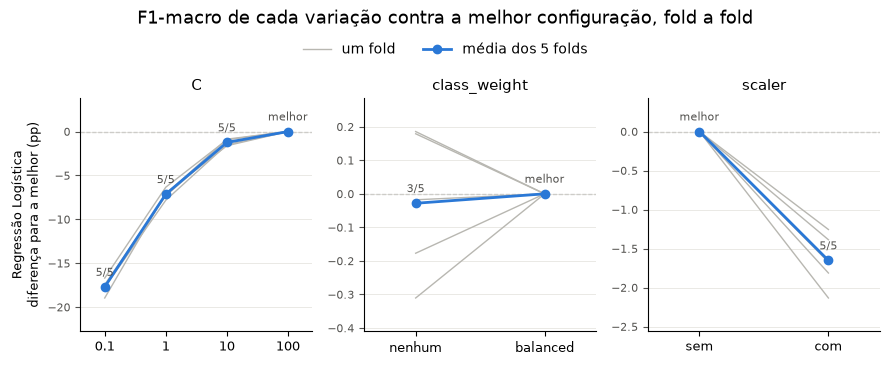

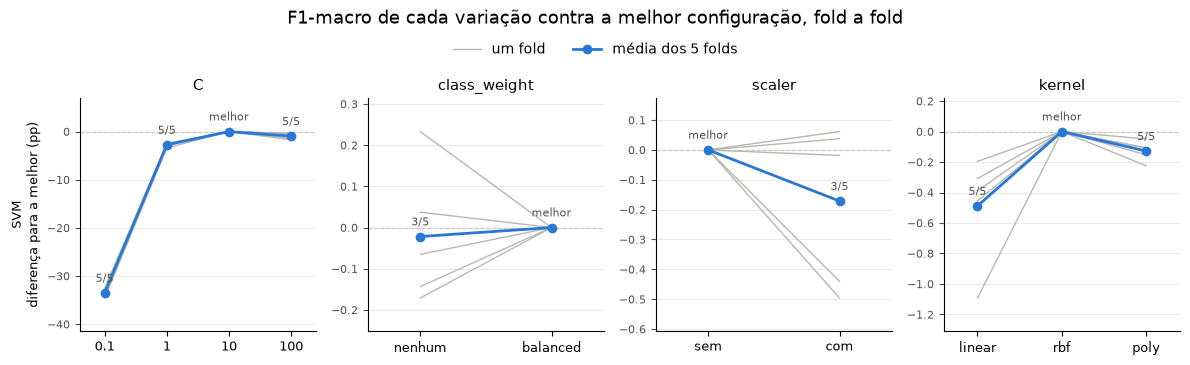

In [144]:
grafico_folds({'Regressão Logística': buscas_reglog_emb_grade['e5_large']}, FATORES_REGLOG_EMB)
plt.show()

grafico_folds({'SVM': buscas_svm_emb['e5_large']}, FATORES_SVM_EMB)
plt.show()

#### Referência sem ajuste
Para mapear o ganho de F1-macro que vem da representação do ganho que vem do ajuste, comparo três pontos para cada modelo:

1. **TF-IDF sem ajuste:** para a Regressão Logística, é o baseline. Para o SVM, são os padrões do `SVC` (kernel RBF, `C=1`, `gamma='scale'`) com o TF-IDF padrão.
2. **Embedding sem ajuste:** mesmo classificador sem ajuste, sem `class_weight` e sem `scaler`, agora com os embeddings.
3. **Embedding ajustado:** o melhor resultado das buscas de hiperparâmetros.

In [145]:
# F1-macro (CV) de uma configuração específica da grade
def f1_config(busca, config):
    i = busca.cv_results_['params'].index(config)
    return busca.cv_results_['mean_test_f1_macro'][i]

sem_ajuste_reglog = {'scaler': 'passthrough', 'clf__C': 1, 'clf__class_weight': None}
sem_ajuste_svm = {'scaler': 'passthrough', 'clf__C': 1, 'clf__class_weight': None,
                  'clf__kernel': 'rbf', 'clf__gamma': 'scale'}
sem_ajuste_svm_tfidf = {
    'tfidf__ngram_range': (1, 1), 'tfidf__stop_words': None, 'tfidf__min_df': 1, 'tfidf__sublinear_tf': False,
    'clf__kernel': 'rbf', 'clf__C': 1, 'clf__gamma': 'scale', 'clf__class_weight': None,
}

modelos = {
    'Regressão Logística': (f1_cv_baseline, busca_reglog.best_score_,
                            buscas_reglog_emb_grade, buscas_reglog_emb, sem_ajuste_reglog),
    'SVM': (f1_config(busca_svm, sem_ajuste_svm_tfidf), busca_svm.best_score_,
            buscas_svm_emb, buscas_svm_emb, sem_ajuste_svm),
}

linhas = []
for modelo, (tfidf_sem, tfidf_ajustado, buscas_grade, buscas_final, config) in modelos.items():
    # o TF-IDF entra como referência: o efeito da representação dele é zero
    linhas.append({'modelo': modelo, 'representação': 'TF-IDF',
                   'sem_ajuste': tfidf_sem, 'ajustado': tfidf_ajustado})
    for encoder in embeddings:
        linhas.append({'modelo': modelo, 'representação': encoder,
                       'sem_ajuste': f1_config(buscas_grade[encoder], config),
                       'ajustado': buscas_final[encoder].best_score_})

tabela_ref = pd.DataFrame(linhas).set_index(['modelo', 'representação'])
tfidf_sem_ajuste = tabela_ref.xs('TF-IDF', level='representação')['sem_ajuste']
tabela_ref['efeito_representação_pp'] = (tabela_ref['sem_ajuste'] - tabela_ref.index.get_level_values('modelo').map(tfidf_sem_ajuste)) * 100
tabela_ref['efeito_ajuste_pp'] = (tabela_ref['ajustado'] - tabela_ref['sem_ajuste']) * 100
tabela_ref.round({'sem_ajuste': 4, 'ajustado': 4, 'efeito_representação_pp': 2, 'efeito_ajuste_pp': 2})

sem_ajuste  ajustado  \
modelo              representação                         
Regressão Logística TF-IDF             0.8441    0.8756   
                    serafim_335m       0.8612    0.9034   
                    e5_base            0.7956    0.9167   
                    e5_large           0.8287    0.9237   
SVM                 TF-IDF             0.8748    0.8830   
                    serafim_335m       0.9031    0.9092   
                    e5_base            0.8866    0.9208   
                    e5_large           0.9017    0.9286   

                                   efeito_representação_pp  efeito_ajuste_pp  
modelo              representação                                             
Regressão Logística TF-IDF                            0.00              3.15  
                    serafim_335m                      1.71              4.22  
                    e5_base                          -4.85             12.11  
                    e5_large                         -1.54              9.50  
SVM                 TF-IDF                            0.00              0.82  
                    serafim_335m                      2.82              0.61  
                    e5_base                           1.18              3.41  
                    e5_large                          2.68              2.70

**Conclusão**

Para ambos os modelos (RegLog e SVM), o melhor encoder foi o `e5_larger`. Por isso, a ablação dos hiperparâmetros só será feita para a combinação de ambos os modelos com esse encoder.

De acordo com a ablação dos hiperparâmetros:

- O `C` continua sendo o hiperparâmetro de maior efeito, e com embeddings o efeito é maior do que com TF-IDF. Na Regressão Logística, voltar ao `C=1` custa 7,13 pp (no TF-IDF custava 2,80 pp). No SVM, o `C=1` custa 2,76 pp, e o `C=0.1` custa 33,51 pp, levando o F1-macro para 0.5935.
- O `StandardScaler` piorou a Regressão Logística em todos os 5 folds, com média de custo de 1,65 pp. No SVM também piorou, o custo foi de 0,17 pp. A ideia de que padronizar ajudaria não se confirmou no `e5_large`.
- O balanceamento de classes (`class_weight`) quase não teve efeito (0,02 a 0,03 pp), assim como no TF-IDF.
- No SVM, o RBF foi o melhor kernel. Porém, a diferença é bem pequena. O linear ficou 0,49 pp abaixo e o polinomial (`degree=2`, `coef0=0`) 0,13 pp abaixo, os dois em 5 de 5 folds. A diferença é consistente, porém pequena.

Em relação à referência sem ajuste:

- Sem ajuste, a Regressão Logística com os embeddings do e5 ficou abaixo do baseline TF-IDF (−4,85 pp no `e5_base` e −1,54 pp no `e5_large`). Só o `serafim_335m` ficou acima (+1,71 pp). Quase todo o ganho veio do ajuste (+9,5 a +12,1 pp), principalmente do `C`. Sem ajuste de hiperparâmetros, a conclusão seria que o e5 é pior que o TF-IDF para RegLog.
- No SVM, os embeddings já ficam acima do TF-IDF mesmo sem ajuste (+1,2 a +2,8 pp), e o ajuste soma mais 0,6 a 3,4 pp.
- Depois do ajuste, todos os encoders superam o melhor modelo com TF-IDF (SVM, 0,8830), com vantagem de +2,0 pp (`serafim_335m` com Regressão Logística, pior performance na cross validation dos modelos com embeddings) a +4,6 pp (`e5_large` com SVM).

#### 5.5 Avaliação no teste
Depois de todas as escolhas feitas com a validação cruzada no treino, avalio os modelos no conjunto de teste e registro os resultados na tabela.

In [146]:
# Regressão Logística ajustada + cada encoder
for encoder, (emb_train, emb_test) in embeddings.items():
    busca = buscas_reglog_emb[encoder]
    y_pred = busca.predict(emb_test)
    registrar_resultado('Regressão Logística ajustada', encoder, y_test, y_pred, busca.best_score_)

tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,Regressão Logística ajustada,e5_large,0.9238,0.9237,0.9264,6.10
1,Regressão Logística ajustada,e5_base,0.9210,0.9167,0.9231,5.77
2,Regressão Logística ajustada,serafim_335m,0.9110,0.9034,0.9119,4.64
3,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
4,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
5,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00
6,Random Forest ajustado,TF-IDF,0.8579,0.8487,0.8558,-0.97
7,XGBoost ajustado,TF-IDF,0.8312,0.8228,0.8313,-3.42


In [147]:
# SVM ajustado + cada encoder
for encoder, (emb_train, emb_test) in embeddings.items():
    busca = buscas_svm_emb[encoder]
    y_pred = busca.predict(emb_test)
    registrar_resultado('SVM ajustado', encoder, y_test, y_pred, busca.best_score_)

tabela_resultados()

,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,e5_large,0.9286,0.9286,0.9307,6.53
1,Regressão Logística ajustada,e5_large,0.9238,0.9237,0.9264,6.10
2,SVM ajustado,e5_base,0.9226,0.9208,0.9245,5.91
3,Regressão Logística ajustada,e5_base,0.9210,0.9167,0.9231,5.77
4,SVM ajustado,serafim_335m,0.9170,0.9092,0.9187,5.32
5,Regressão Logística ajustada,serafim_335m,0.9110,0.9034,0.9119,4.64
6,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
7,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
8,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00
9,Random Forest ajustado,TF-IDF,0.8579,0.8487,0.8558,-0.97


**Escolha do melhor modelo**

A `tabela_resultados` é ordenada pelo F1-macro do teste, mas o melhor modelo é escolhido pelo F1-macro da validação cruzada. Se eu escolhesse pelo teste, ele deixaria de ser uma estimativa independente do desempenho do modelo escolhido.

In [148]:
# Mesma tabela, ordenada pelo F1-macro da validação cruzada
tabela_cv = tabela_resultados().sort_values('f1_macro_cv', ascending=False).reset_index(drop=True)

melhor = tabela_cv.iloc[0]
print(f"Melhor pela validação cruzada: {melhor['modelo']} + {melhor['representação']} "
      f"(F1-macro CV = {melhor['f1_macro_cv']:.4f}, teste = {melhor['f1_macro']:.4f})")
tabela_cv.sort_values(by='f1_macro',ascending=False)

Melhor pela validação cruzada: SVM ajustado + e5_large (F1-macro CV = 0.9286, teste = 0.9307)


,modelo,representação,acurácia,f1_macro_cv,f1_macro,ganho_f1_pp
0,SVM ajustado,e5_large,0.9286,0.9286,0.9307,6.53
1,Regressão Logística ajustada,e5_large,0.9238,0.9237,0.9264,6.10
2,SVM ajustado,e5_base,0.9226,0.9208,0.9245,5.91
3,Regressão Logística ajustada,e5_base,0.9210,0.9167,0.9231,5.77
4,SVM ajustado,serafim_335m,0.9170,0.9092,0.9187,5.32
5,Regressão Logística ajustada,serafim_335m,0.9110,0.9034,0.9119,4.64
6,SVM ajustado,TF-IDF,0.8923,0.8830,0.8922,2.67
7,Regressão Logística ajustada,TF-IDF,0.8915,0.8756,0.8906,2.52
9,Regressão Logística (baseline),TF-IDF,0.8671,0.8441,0.8654,0.00
8,Random Forest ajustado,TF-IDF,0.8579,0.8487,0.8558,-0.97


**Comparação entre validação cruzada e teste**

- O F1-macro do teste ficou acima do F1-macro da validação cruzada nos 6 modelos, provavelmente pelo mesmo motivo dos modelos de TF-IDF, sendo porque o modelo final é treinado com o treino inteiro, enquanto em cada fold ele treina com 80% dele.
- O SVM ficou à frente da Regressão Logística nos três encoders por pouco.
- No teste, todos os modelos com embeddings superam o melhor modelo com TF-IDF. Sobre o baseline, o ganho vai de 4,64 a 6,53 pp.

### 6. Resumo da modelagem
O gráfico reúne todos os modelos avaliados no teste, ordenados pelo F1-macro da validação cruzada, que foi o critério de escolha. Para cada modelo, o ponto azul é o F1-macro na validação cruzada e o laranja é o F1-macro no teste, com o valor ao lado.

O eixo não começa em zero, porque as diferenças entre os modelos de embeddings são de décimos de ponto percentual e não apareceriam numa escala de 0 a 1.

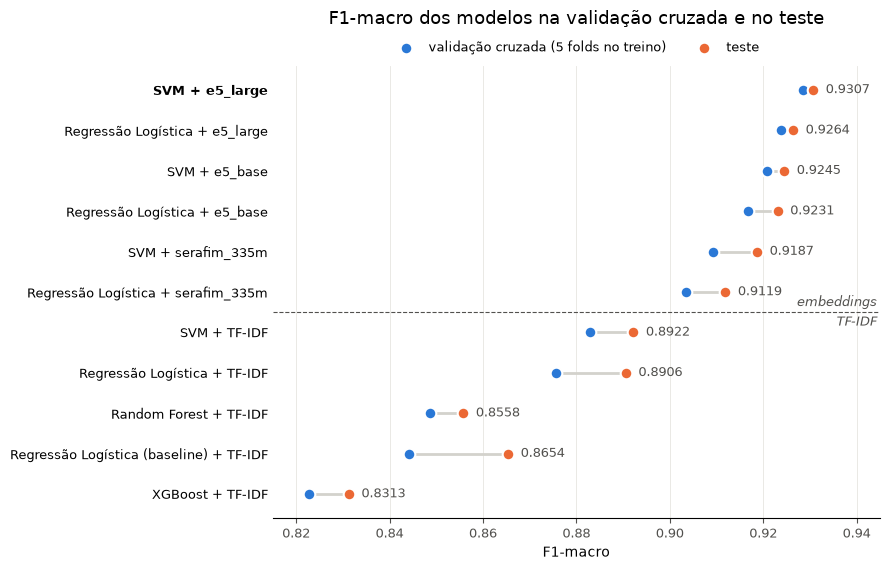

In [149]:
# F1-macro de cada modelo na validação cruzada e no teste
# Ordenado pelo F1-macro da validação cruzada, que é o critério de escolha (o melhor fica no topo)
resumo = tabela_resultados().sort_values('f1_macro_cv').reset_index(drop=True)
nomes = (resumo['modelo'].str.replace(' ajustada', '').str.replace(' ajustado', '')
         + ' + ' + resumo['representação'])

COR_CV = '#2a78d6'     # azul: validação cruzada
COR_TESTE = '#eb6834'  # laranja: teste
COR_LIGACAO = '#d3d2cc'

fig, ax = plt.subplots(figsize=(9, 5.8))
y = np.arange(len(resumo))

# linha ligando os dois pontos de cada modelo
ax.hlines(y, resumo['f1_macro_cv'], resumo['f1_macro'], color=COR_LIGACAO, linewidth=2, zorder=1)
ax.scatter(resumo['f1_macro_cv'], y, s=70, color=COR_CV, edgecolors='white', linewidths=1.5,
           zorder=2, label='validação cruzada (5 folds no treino)')
ax.scatter(resumo['f1_macro'], y, s=70, color=COR_TESTE, edgecolors='white', linewidths=1.5,
           zorder=3, label='teste')

# F1-macro do teste à direita de cada modelo
for yi, (cv, teste) in enumerate(zip(resumo['f1_macro_cv'], resumo['f1_macro'])):
    ax.annotate(f'{teste:.4f}', (max(cv, teste), yi), xytext=(9, 0),
                textcoords='offset points', va='center', fontsize=9, color=COR_TEXTO)

# separação entre os modelos com TF-IDF (embaixo) e com embeddings (em cima)
n_tfidf = int((resumo['representação'] == 'TF-IDF').sum())
ax.axhline(n_tfidf - 0.5, color=COR_TEXTO, linewidth=0.8, linestyle='--')
for texto, posicao in [('TF-IDF', n_tfidf - 0.75), ('embeddings', n_tfidf - 0.25)]:
    ax.text(0.995, posicao, texto, transform=ax.get_yaxis_transform(), ha='right',
            va='center', fontsize=9, color=COR_TEXTO, style='italic')

ax.set_yticks(y, nomes, fontsize=9)
ax.get_yticklabels()[-1].set_fontweight('bold')  # melhor modelo pela validação cruzada
ax.set_xlim(0.815, 0.945)
ax.set_ylim(-0.6, len(resumo) - 0.4)
ax.set_xlabel('F1-macro', fontsize=10)
ax.tick_params(axis='x', labelsize=9, colors=COR_TEXTO)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', color='#e6e5e0', linewidth=0.6)
ax.set_axisbelow(True)
for lado in ['top', 'right', 'left']:
    ax.spines[lado].set_visible(False)

ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False, fontsize=9)
ax.set_title('F1-macro dos modelos na validação cruzada e no teste', fontsize=13, pad=30)
fig.tight_layout()
plt.show()

**Resultado**

O melhor modelo é o **SVM sobre os embeddings do `e5_large`** (kernel RBF, `C=10`, `class_weight='balanced'`, sem `StandardScaler`). Ele foi escolhido pela validação cruzada (F1-macro de 0,9286) e confirmado no teste, com **0,9307 de F1-macro** e 0,9286 de acurácia, +6,53 pp de F1-macro sobre o baseline.

Principais conclusões:

- **A representação impactou mais do que o classificador:** Os 6 modelos com embeddings ficaram acima de todos os modelos com TF-IDF. O pior dos embeddings (Regressão Logística + `serafim_335m`, 0,9119) supera o melhor com TF-IDF (SVM, 0,8922).
- **O ajuste de hiperparâmetros foi extremamente necessário, principalmente nos embeddings:** O `C` foi o hiperparâmetro de maior efeito. Sem ajuste, a Regressão Logística com os embeddings do e5 ficava abaixo do baseline com TF-IDF.
- **Os modelos de árvore não funcionaram bem com TF-IDF:** No teste, Random Forest e XGBoost ficaram abaixo do baseline, como esperado pela forma como as árvores lidam com a matriz esparsa. Não treinei árvores sobre os embeddings, pois elas dividem os dados uma dimensão por vez, e nos embeddings uma dimensão sozinha não tem significado. A informação está na combinação de todas elas. Por isso, o resultado esperado também seria abaixo dos modelos lineares.
- **A validação cruzada foi uma boa estimativa do teste:** O F1-macro do teste ficou acima da validação cruzada em todos os modelos, e a ordem entre eles é a mesma, com exceção do Random Forest e o baseline, que trocam de posição.

O próximo passo é avaliar o SVM + `e5_large` em detalhe (desempenho por classe, pares de categorias que ele confunde, etc.) e compará-lo com a classificação feita por LLMs.